In [1]:
%pip -q install kagglehub torch torchvision scikit-learn pandas numpy matplotlib pillow tqdm

## 1. Download the dataset automatically (Kaggle authentication required)

Dataset: Masoud Nickparvar, *Brain Tumor MRI Dataset*, Version 1 (7,023 images):
https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/1

This notebook uses `kagglehub` and asks for Kaggle username and API key via hidden input prompts. Create/download a Kaggle API token from https://www.kaggle.com/settings. Never paste your token into notebook source or share it publicly.

In [2]:
import os, sys, json, random, hashlib, shutil, getpass, subprocess, zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Securely prompt for Kaggle credentials in the notebook runtime.
# These are kept in the current runtime environment only.
if not (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")):
    print("Enter Kaggle API credentials. Create a token at https://www.kaggle.com/settings")
    os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ").strip()
    os.environ["KAGGLE_KEY"] = getpass.getpass("Kaggle API key (hidden): ").strip()

assert os.environ["KAGGLE_USERNAME"] and os.environ["KAGGLE_KEY"], "Kaggle credentials are required."

import kagglehub
DATA_CACHE = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset", force_download=False))
print("Downloaded dataset directory:", DATA_CACHE)
print("Top-level entries:", [p.name for p in DATA_CACHE.iterdir()][:20])

Enter Kaggle API credentials. Create a token at https://www.kaggle.com/settings
Kaggle username: tejapampana
Kaggle API key (hidden): ··········
Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Downloaded dataset directory: /kaggle/input/brain-tumor-mri-dataset
Top-level entries: ['Training', 'Testing']


## 2. Find image folders and audit counts

Expected Version 1 totals:
- Glioma: 1,621
- Meningioma: 1,645
- Pituitary: 1,757
- No tumor: 2,000
- Total: 7,023

If counts differ, stop and inspect the dataset version. Newer versions may contain 7,200 images and are not the same release.

In [3]:
CLASS_ALIASES = {
    "glioma": "glioma", "glioma_tumor": "glioma", "glioma tumor": "glioma",
    "meningioma": "meningioma", "meningioma_tumor": "meningioma", "meningioma tumor": "meningioma",
    "notumor": "notumor", "no_tumor": "notumor", "no tumor": "notumor",
    "pituitary": "pituitary", "pituitary_tumor": "pituitary", "pituitary tumor": "pituitary",
}
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def canonical_class(name):
    return CLASS_ALIASES.get(name.strip().lower().replace("-", "_"))

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

def scan_dataset(root):
    # Pick the most likely class directories and avoid duplicate path records.
    records, corrupt = [], []
    seen = set()
    for folder in root.rglob("*"):
        if not folder.is_dir():
            continue
        cls = canonical_class(folder.name)
        if cls is None:
            continue
        for path in folder.rglob("*"):
            if not path.is_file() or path.suffix.lower() not in VALID_EXTS:
                continue
            rp = str(path.resolve())
            if rp in seen:
                continue
            seen.add(rp)
            try:
                with Image.open(path) as im:
                    im.verify()
                with Image.open(path) as im:
                    w, h, mode = im.width, im.height, im.mode
                records.append({"path": rp, "class_name": cls, "width": w, "height": h,
                                "mode": mode, "sha256": sha256_file(path)})
            except Exception as e:
                corrupt.append({"path": rp, "error": repr(e)})
    df = pd.DataFrame(records)
    if df.empty:
        raise RuntimeError("Could not find images under four class folders. Inspect downloaded folder structure.")
    return df, pd.DataFrame(corrupt)

audit_df, corrupt_df = scan_dataset(DATA_CACHE)
counts = audit_df.class_name.value_counts().reindex(CLASS_NAMES, fill_value=0)
print("Counts by class:\n", counts)
print("Total:", len(audit_df), "| Expected Version 1 total: 7023")
print("Corrupt/unreadable:", len(corrupt_df))
display(audit_df.head())
if len(corrupt_df):
    display(corrupt_df.head(20))

EXPECTED = {"glioma":1621, "meningioma":1645, "pituitary":1757, "notumor":2000}
print("Matches expected Version 1 counts:", counts.to_dict() == EXPECTED)

Counts by class:
 class_name
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800
Name: count, dtype: int64
Total: 7200 | Expected Version 1 total: 7023
Corrupt/unreadable: 0


,path,class_name,width,height,mode,sha256
0,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,512,512,RGB,e91215407672f252077cdd5c063455438c1c55ce0a8c76...
1,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,512,512,L,4ce2b7db480ff8e1ebc8fe225b48f1197a12d87d9770b2...
2,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,512,512,RGB,a621d023075294efa0c20daa710bb9ce0582e5c3e5b003...
3,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,512,512,L,4585128888c08733ded0da513a9a06d9036a3056904983...
4,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,512,512,RGB,fa835932d746ab2a7dfd382f13c8e7be99a2f60855bc48...


Matches expected Version 1 counts: False


## 3. Exact duplicates and data visualization

Exact duplicate hashes are reported. This does not detect visually similar or near-duplicate images; patient/source identifiers are not guaranteed in this dataset.

Images in exact-duplicate groups: 340


,path,class_name,width,height,mode,sha256
6942,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,249,238,RGB,04aa41d8514362877d7f8fd81e543bc8584e4a6ba1ac02...
6889,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma,249,238,RGB,04aa41d8514362877d7f8fd81e543bc8584e4a6ba1ac02...
1762,/kaggle/input/brain-tumor-mri-dataset/Training...,notumor,354,443,RGB,05ec18666c6b751b8845a93824ea25c9bb251606b71f76...
1536,/kaggle/input/brain-tumor-mri-dataset/Training...,notumor,354,443,RGB,05ec18666c6b751b8845a93824ea25c9bb251606b71f76...
2957,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,L,089a7ad8107e9ef50fc7c35e7407b18fcda170be370774...
3562,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,L,089a7ad8107e9ef50fc7c35e7407b18fcda170be370774...
2959,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,RGB,09b9031e30e757eb6e648686f0ca412357e86895ebbc52...
3738,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,RGB,09b9031e30e757eb6e648686f0ca412357e86895ebbc52...
4060,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,L,0f673459b5dba7f9dab9a6a32309e2c89ddf4bb9b799d3...
3900,/kaggle/input/brain-tumor-mri-dataset/Training...,meningioma,512,512,L,0f673459b5dba7f9dab9a6a32309e2c89ddf4bb9b799d3...


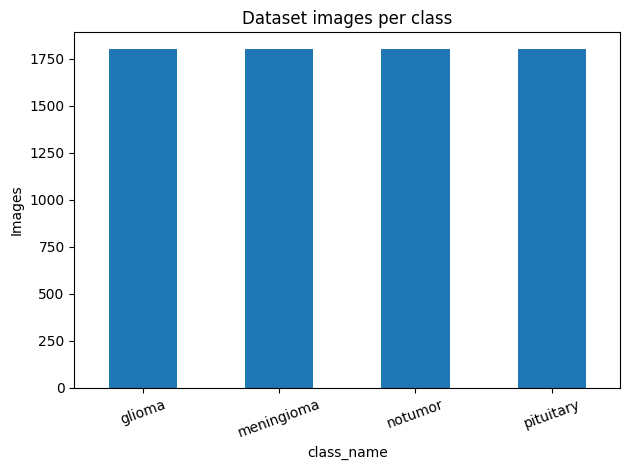

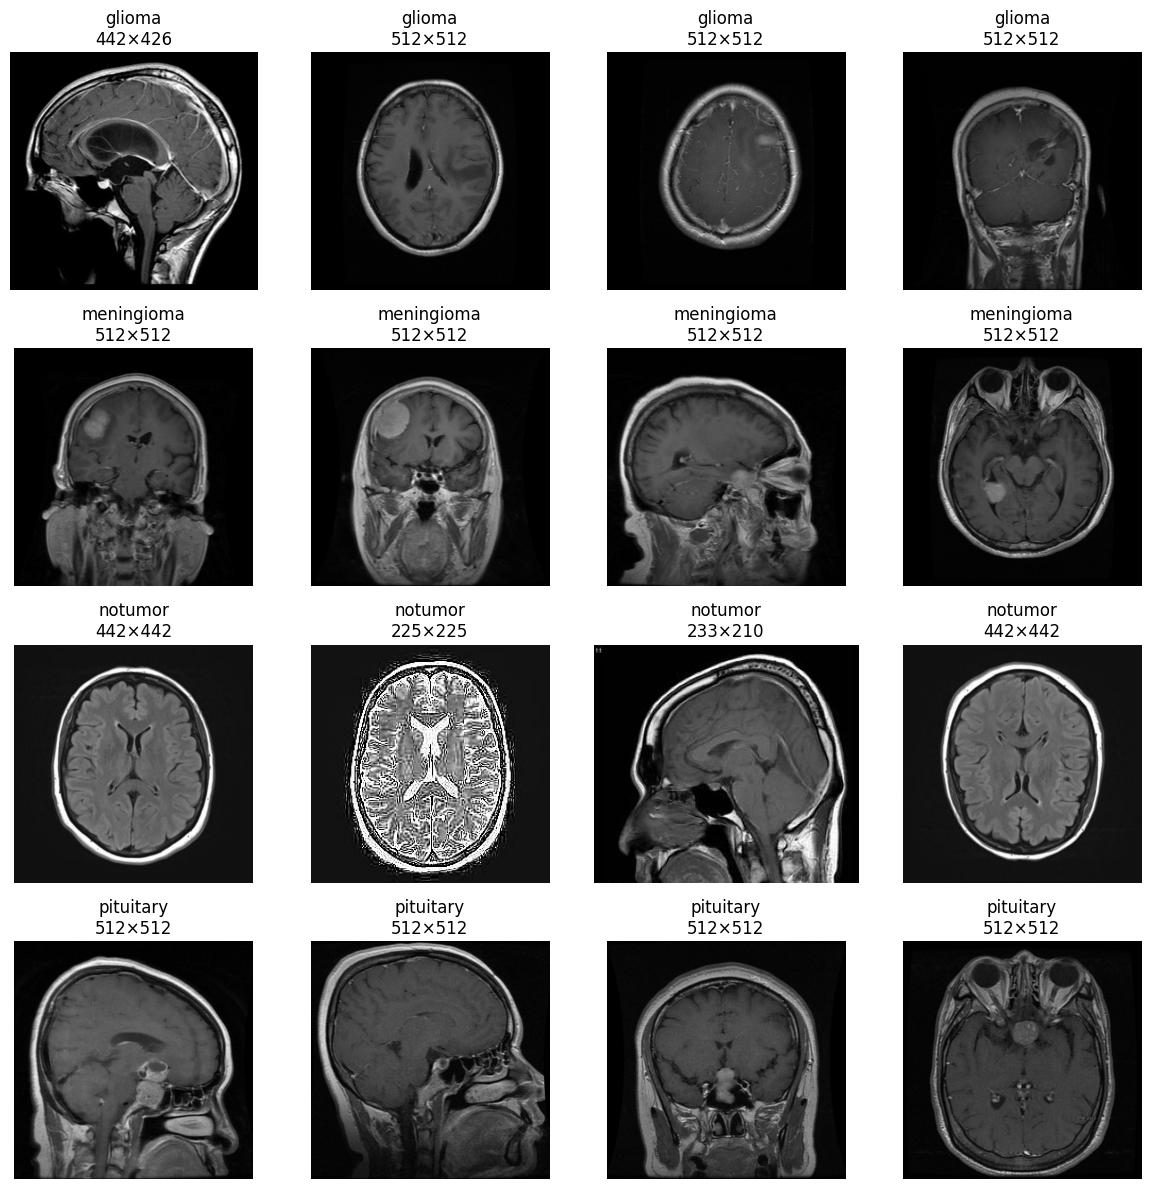

In [4]:
dupes = audit_df[audit_df.duplicated("sha256", keep=False)].sort_values("sha256")
print("Images in exact-duplicate groups:", len(dupes))
display(dupes.head(30))

import matplotlib.pyplot as plt
ax = counts.plot(kind="bar", title="Dataset images per class", rot=20)
ax.set_ylabel("Images")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for r, cls in enumerate(CLASS_NAMES):
    sample = audit_df[audit_df.class_name == cls].sample(min(4, (audit_df.class_name == cls).sum()), random_state=SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        with Image.open(row.path) as im:
            axes[r,c].imshow(im.copy(), cmap="gray" if im.mode == "L" else None)
        axes[r,c].set_title(f"{cls}\n{row.width}×{row.height}")
        axes[r,c].axis("off")
    for c in range(len(sample), 4):
        axes[r,c].axis("off")
plt.tight_layout()
plt.show()

## 4. Split data before augmentation

We use a stratified 70/15/15 train/validation/test split. Exact duplicate files are grouped together where possible to avoid exact-hash leakage. The public dataset does not reliably provide patient IDs, so this cannot guarantee patient-independent evaluation. Do not tune based on test results.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import train_test_split

# Exact duplicate groups cannot cross splits.
try:
    outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    trainval_idx, test_idx = next(outer.split(audit_df, audit_df.class_name, groups=audit_df.sha256))
    trainval = audit_df.iloc[trainval_idx].copy()
    test_df = audit_df.iloc[test_idx].copy()
    inner = StratifiedGroupKFold(n_splits=round(1/(0.15/0.85)), shuffle=True, random_state=SEED)
    tr_idx, va_idx = next(inner.split(trainval, trainval.class_name, groups=trainval.sha256))
    train_df = trainval.iloc[tr_idx].copy()
    val_df = trainval.iloc[va_idx].copy()
    split_method = "StratifiedGroupKFold grouped by exact SHA-256; patient independence unverified"
except Exception as e:
    print("Group split failed; falling back to stratified image-level split:", repr(e))
    trainval, test_df = train_test_split(audit_df, test_size=0.15, random_state=SEED, stratify=audit_df.class_name)
    train_df, val_df = train_test_split(trainval, test_size=0.15/0.85, random_state=SEED, stratify=trainval.class_name)
    split_method = "Stratified image-level; patient independence unverified"

print(split_method)
print("Train/val/test:", len(train_df), len(val_df), len(test_df))
display(pd.crosstab(pd.concat([
    train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")
]).split, pd.concat([
    train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")
]).class_name))

StratifiedGroupKFold grouped by exact SHA-256; patient independence unverified
Train/val/test: 5143 1026 1031


class_name,glioma,meningioma,notumor,pituitary
split,,,,
test,246,245,257,283
train,1294,1283,1281,1285
validation,260,272,262,232


## 5. Paper-informed preprocessing and augmentation

The paper describes resizing to 200×200, grayscale input, pixel scaling to [0,1], and Gaussian smoothing. Gaussian blur is enabled here as the paper-informed default, but its exact parameters are not clearly standardized in the paper; treat this as an implementation choice. Augmentation is applied to training images only.

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 200
BATCH_SIZE = 32
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10, interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),  # [0,1]
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.GaussianBlur(kernel_size=3, sigma=0.5),
    transforms.ToTensor(),
])

class BrainMRIDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = {c:i for i,c in enumerate(CLASS_NAMES)}
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row.path) as im:
            image = im.convert("L")
        return self.transform(image), self.class_to_idx[row.class_name], row.path

train_ds = BrainMRIDataset(train_df, train_transform)
val_ds = BrainMRIDataset(val_df, eval_transform)
test_ds = BrainMRIDataset(test_df, eval_transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print("Device:", DEVICE, "| Train batches:", len(train_loader))

Device: cuda | Train batches: 161


## 6. Custom CNN from scratch

Six convolution layers with filter progression 64→128→128→256→256→512 and 7×7 kernels reflect the broad architecture described in the paper. We use global average pooling to limit the parameter count; if the paper's exact layer diagram specifies a different classifier, document this as a deviation. No pretrained weights are loaded.

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=7):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=kernel, padding=kernel//2, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
    def forward(self, x):
        return self.block(x)

class CustomCNN(nn.Module):
    def __init__(self, num_classes=4, dropout=0.4):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1,64), ConvBlock(64,128), ConvBlock(128,128),
            ConvBlock(128,256), ConvBlock(256,256), ConvBlock(256,512)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(512,128), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(128,num_classes)
        )
    def forward(self,x):
        return self.classifier(self.pool(self.features(x)))

model = CustomCNN().to(DEVICE)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
with torch.no_grad():
    print("Output shape:", model(torch.zeros(2,1,IMAGE_SIZE,IMAGE_SIZE,device=DEVICE)).shape)

Parameters: 12,515,652
Output shape: torch.Size([2, 4])


## 7. Train with validation-based checkpointing and early stopping

The paper's text has optimizer inconsistencies. This notebook explicitly uses SGD with momentum and learning rate 0.001, matching the experiment section. Validation loss selects the checkpoint; the test set is not touched during training.

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import copy, time

EPOCHS = 40
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 8

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR, momentum=0.9, weight_decay=WEIGHT_DECAY, nesterov=True)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

def epoch_pass(loader, training):
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    for x,y,_ in loader:
        x,y = x.to(DEVICE), y.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits,y)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item()*len(y)
        correct += (logits.argmax(1)==y).sum().item()
        n += len(y)
    return total_loss/max(n,1), correct/max(n,1)

history=[]
best_val=float("inf")
best_state=None
bad_epochs=0
for epoch in range(1,EPOCHS+1):
    tr_loss,tr_acc=epoch_pass(train_loader,True)
    va_loss,va_acc=epoch_pass(val_loader,False)
    scheduler.step(va_loss)
    history.append({"epoch":epoch,"train_loss":tr_loss,"train_acc":tr_acc,"val_loss":va_loss,"val_acc":va_acc,"lr":optimizer.param_groups[0]["lr"]})
    print(f"{epoch:02d}/{EPOCHS} train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_loss={va_loss:.4f} val_acc={va_acc:.4f}")
    if va_loss < best_val:
        best_val=va_loss
        best_state=copy.deepcopy(model.state_dict())
        bad_epochs=0
        torch.save({"model_state_dict":best_state,"class_names":CLASS_NAMES,"image_size":IMAGE_SIZE,
                    "config":{"model":"CustomCNN","pretrained":False,"optimizer":"SGD","lr":LR,
                              "batch_size":BATCH_SIZE,"seed":SEED,"split_method":split_method}},
                   "/content/best_custom_cnn.pt")
    else:
        bad_epochs+=1
    if bad_epochs >= PATIENCE:
        print("Early stopping.")
        break

history_df=pd.DataFrame(history)
history_df.to_csv("/content/training_history.csv",index=False)
display(history_df.tail())

01/40 train_loss=0.8099 train_acc=0.6852 val_loss=0.7739 val_acc=0.6637
02/40 train_loss=0.5385 train_acc=0.7906 val_loss=0.5203 val_acc=0.7700
03/40 train_loss=0.4436 train_acc=0.8359 val_loss=0.3680 val_acc=0.8558
04/40 train_loss=0.3371 train_acc=0.8812 val_loss=0.6595 val_acc=0.7329
05/40 train_loss=0.3196 train_acc=0.8839 val_loss=0.5395 val_acc=0.8294
06/40 train_loss=0.2443 train_acc=0.9125 val_loss=0.3921 val_acc=0.8480
07/40 train_loss=0.2187 train_acc=0.9216 val_loss=0.2660 val_acc=0.9035
08/40 train_loss=0.2015 train_acc=0.9288 val_loss=0.8695 val_acc=0.7563
09/40 train_loss=0.1759 train_acc=0.9419 val_loss=0.1768 val_acc=0.9415
10/40 train_loss=0.1496 train_acc=0.9479 val_loss=0.3781 val_acc=0.8772
11/40 train_loss=0.1237 train_acc=0.9596 val_loss=0.1650 val_acc=0.9493
12/40 train_loss=0.1060 train_acc=0.9658 val_loss=0.4435 val_acc=0.8704
13/40 train_loss=0.1078 train_acc=0.9640 val_loss=0.7461 val_acc=0.7924
14/40 train_loss=0.1020 train_acc=0.9636 val_loss=0.1669 val_acc

,epoch,train_loss,train_acc,val_loss,val_acc,lr
29,30,0.016988,0.994167,0.129497,0.971735,0.000125
30,31,0.014329,0.996306,0.122221,0.975634,0.000125
31,32,0.011433,0.997083,0.123698,0.972710,0.000125
32,33,0.009583,0.997472,0.126789,0.976608,0.000125
33,34,0.010645,0.996889,0.122206,0.975634,0.000063


## 8. Training curves

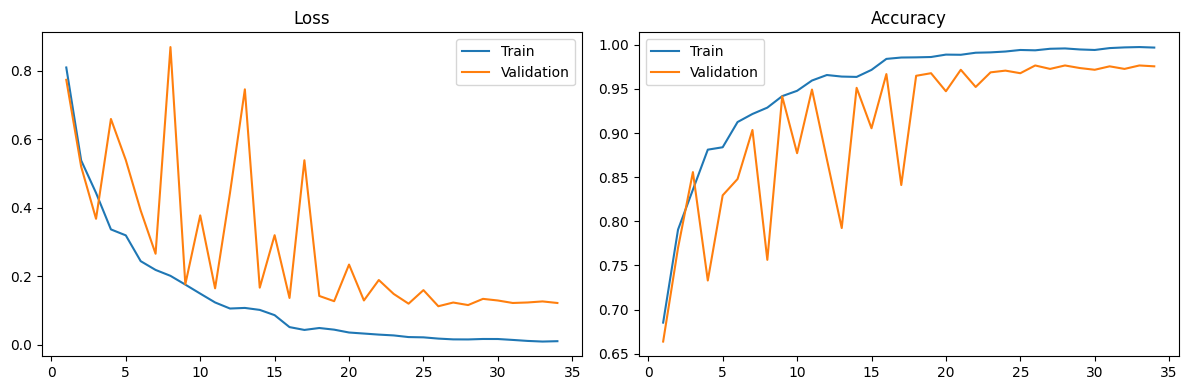

In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history_df.epoch,history_df.train_loss,label="Train")
axes[0].plot(history_df.epoch,history_df.val_loss,label="Validation")
axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(history_df.epoch,history_df.train_acc,label="Train")
axes[1].plot(history_df.epoch,history_df.val_acc,label="Validation")
axes[1].set_title("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. One final evaluation on held-out test data

Use the selected validation checkpoint. Accuracy alone is insufficient: inspect per-class recall and confusion matrix. Do not claim the result generalizes clinically or to unseen hospitals.

Test accuracy: 97.1872%
              precision    recall  f1-score   support

      glioma     0.9834    0.9634    0.9733       246
  meningioma     0.9639    0.9796    0.9717       245
     notumor     0.9470    0.9728    0.9597       257
   pituitary     0.9928    0.9717    0.9821       283

    accuracy                         0.9719      1031
   macro avg     0.9718    0.9719    0.9717      1031
weighted avg     0.9722    0.9719    0.9719      1031



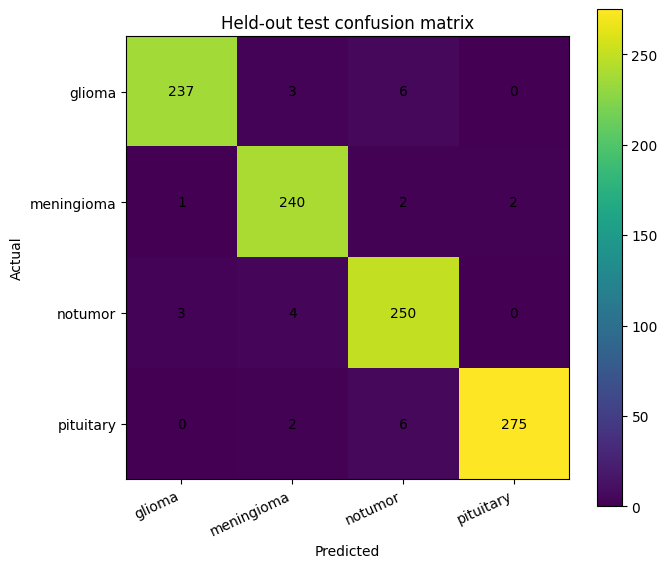

Saved /content/custom_cnn_final.pt, /content/training_history.csv, /content/test_predictions.csv


In [10]:
checkpoint=torch.load("/content/best_custom_cnn.pt",map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
y_true,y_pred,paths=[],[],[]
with torch.no_grad():
    for x,y,p in test_loader:
        logits=model(x.to(DEVICE))
        pred=logits.argmax(1).cpu().numpy().tolist()
        y_true.extend(y.numpy().tolist())
        y_pred.extend(pred)
        paths.extend(list(p))

print("Test accuracy:", f"{accuracy_score(y_true,y_pred):.4%}")
print(classification_report(y_true,y_pred,target_names=CLASS_NAMES,digits=4,zero_division=0))
cm=confusion_matrix(y_true,y_pred)
fig,ax=plt.subplots(figsize=(7,6))
im=ax.imshow(cm)
ax.set_xticks(range(4),CLASS_NAMES,rotation=25,ha="right")
ax.set_yticks(range(4),CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Held-out test confusion matrix")
for i in range(4):
    for j in range(4): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

pd.DataFrame({"path":paths,"true_label":[CLASS_NAMES[i] for i in y_true],
              "predicted_label":[CLASS_NAMES[i] for i in y_pred],
              "correct":np.array(y_true)==np.array(y_pred)}).to_csv("/content/test_predictions.csv",index=False)
torch.save({"model_state_dict":model.state_dict(),"class_names":CLASS_NAMES,"image_size":IMAGE_SIZE},
           "/content/custom_cnn_final.pt")
print("Saved /content/custom_cnn_final.pt, /content/training_history.csv, /content/test_predictions.csv")

In [24]:
y_true_arr = np.array(y_true)
y_pred_arr = np.array(y_pred)

print("Test images:", len(test_ds))
print("Correct predictions:", (y_true_arr == y_pred_arr).sum())
print("Accuracy:", (y_true_arr == y_pred_arr).mean() * 100)

Test images: 1031
Correct predictions: 1002
Accuracy: 97.18719689621726


Total misclassified: 29


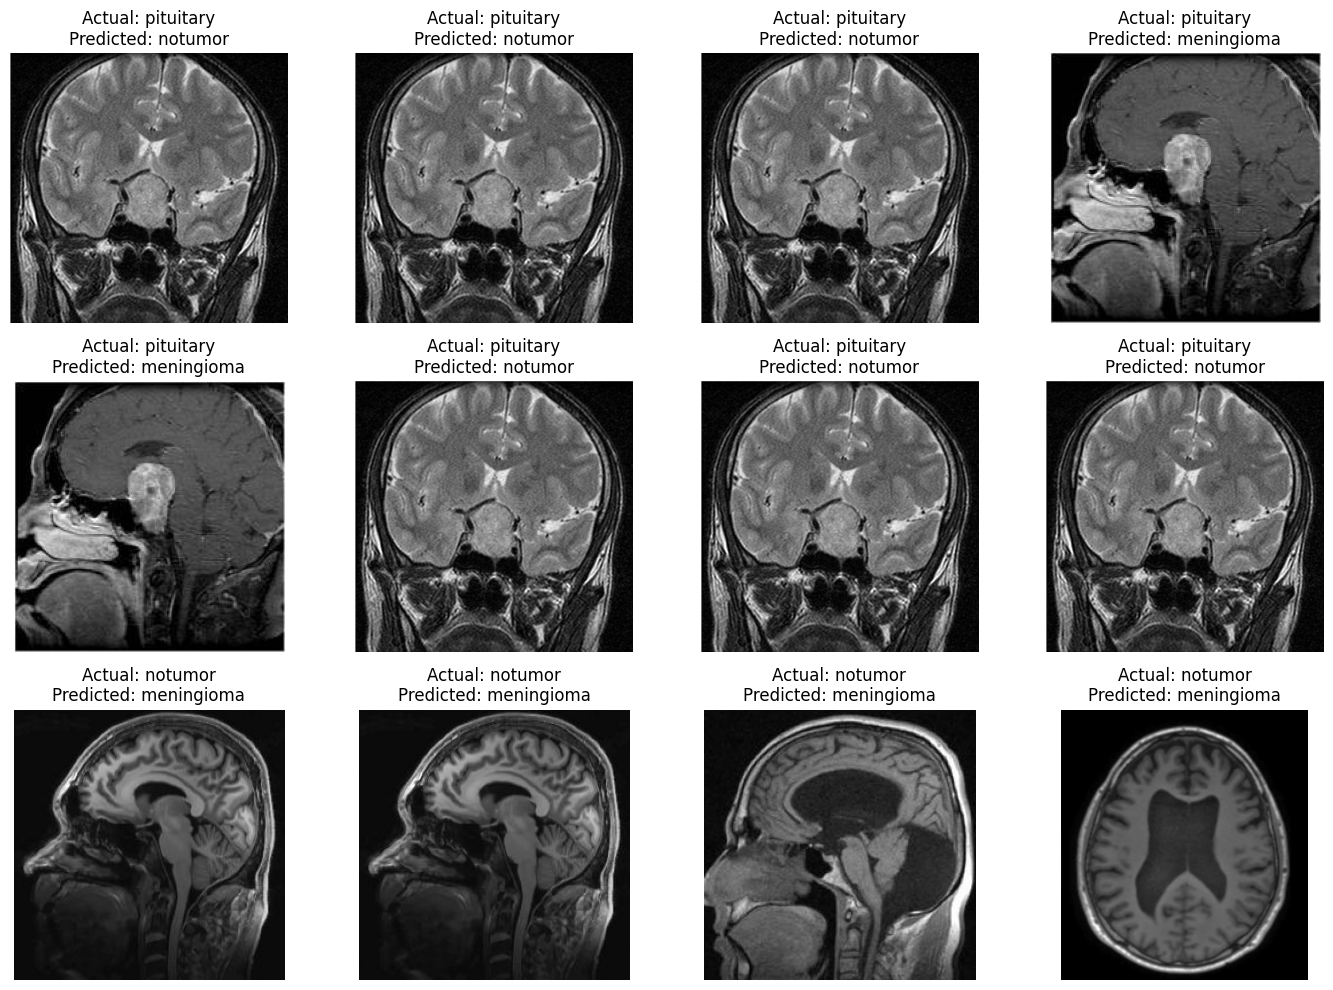

In [25]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

errors = np.where(y_true_arr != y_pred_arr)[0]
print("Total misclassified:", len(errors))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, idx in zip(axes, errors[:12]):
    img_path = paths[idx]
    with Image.open(img_path) as img:
        ax.imshow(img.convert("L"), cmap="gray")
    ax.set_title(
        f"Actual: {CLASS_NAMES[y_true_arr[idx]]}\n"
        f"Predicted: {CLASS_NAMES[y_pred_arr[idx]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
from collections import Counter
import hashlib

# Exact duplicate images within test set
hashes = []
for path in paths:
    with open(path, "rb") as f:
        hashes.append(hashlib.sha256(f.read()).hexdigest())

counts = Counter(hashes)
duplicates = {h: n for h, n in counts.items() if n > 1}

print("Test images:", len(paths))
print("Unique exact hashes:", len(set(hashes)))
print("Duplicate hash groups:", len(duplicates))

Test images: 1031
Unique exact hashes: 1002
Duplicate hash groups: 24


In [27]:
from collections import defaultdict
import hashlib
import os

def get_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

split_paths = {
    "train": train_df["path"].tolist(),
    "val": val_df["path"].tolist(),
    "test": test_df["path"].tolist()
}

hash_to_files = defaultdict(list)
for split, paths_list in split_paths.items():
    for p in paths_list:
        hash_to_files[get_hash(p)].append((split, p))

duplicate_groups = {
    h: files for h, files in hash_to_files.items()
    if len(files) > 1
}

print("Total duplicate groups across all splits:", len(duplicate_groups))

cross_split_groups = {
    h: files for h, files in duplicate_groups.items()
    if len(set(split for split, _ in files)) > 1
}

print("Duplicate groups crossing splits:", len(cross_split_groups))
for h, files in list(cross_split_groups.items())[:10]:
    print("\nDuplicate group:")
    for split, p in files:
        print(split, p)

Total duplicate groups across all splits: 153
Duplicate groups crossing splits: 0


In [28]:
import hashlib
import numpy as np

seen = set()
unique_indices = []

for i, path in enumerate(paths):
    with open(path, "rb") as f:
        h = hashlib.sha256(f.read()).hexdigest()
    if h not in seen:
        seen.add(h)
        unique_indices.append(i)

unique_indices = np.array(unique_indices)
unique_accuracy = np.mean(
    y_true_arr[unique_indices] == y_pred_arr[unique_indices]
)

print("Unique test images:", len(unique_indices))
print(f"Unique-image accuracy: {unique_accuracy * 100:.2f}%")

Unique test images: 1002
Unique-image accuracy: 97.80%


### 11. Test the Model on Your Own Unseen MRI Scans
Use this cell to upload any new brain MRI image from your local computer and see what our trained custom CNN predicts.

Saving pituitary_2.jpg to pituitary_2.jpg
Processing uploaded file: pituitary_2.jpg


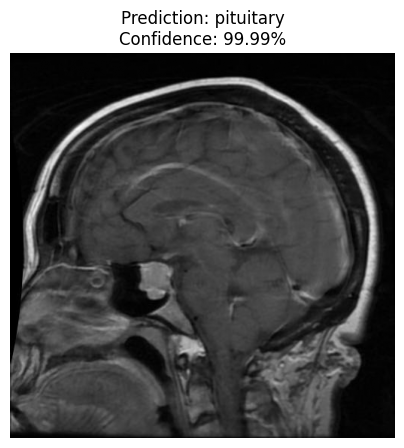

  - glioma: 0.00%
  - meningioma: 0.01%
  - notumor: 0.00%
  - pituitary: 99.99%


In [30]:
from google.colab import files
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

# Prompt user to upload local brain tumor MRI image files
uploaded = files.upload()

# Ensure the model is loaded and in evaluation mode
checkpoint = torch.load("/content/best_custom_cnn.pt", map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

for filename in uploaded.keys():
    print(f"Processing uploaded file: {filename}")

    # 1. Load image and convert to grayscale
    with Image.open(filename) as raw_img:
        img_gray = raw_img.convert("L")

    # 2. Apply our exact evaluation transformations
    img_tensor = eval_transform(img_gray).unsqueeze(0).to(DEVICE) # Add batch dimension

    # 3. Model Inference
    with torch.no_grad():
        outputs = model(img_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]
        predicted_class_idx = outputs.argmax(1).item()
        predicted_class_name = CLASS_NAMES[predicted_class_idx]
        confidence = probabilities[predicted_class_idx].item() * 100

    # 4. Display input image alongside prediction confidence
    plt.figure(figsize=(5, 5))
    plt.imshow(img_gray, cmap="gray")
    plt.title(f"Prediction: {predicted_class_name}\nConfidence: {confidence:.2f}%")
    plt.axis("off")
    plt.show()

    # Print raw class breakdown probabilities
    for idx, name in enumerate(CLASS_NAMES):
        print(f"  - {name}: {probabilities[idx].item() * 100:.2f}%")